# Lab 09 — Learning from text

*Count words, weigh them, and find out what a model can and cannot read*

**Goal.** Turn raw messages into a table a model can read, build a spam filter whose threshold protects real messages, classify questions into 77 intents and find where that classifier fails, search stored questions by similarity, and learn word vectors that repair what counting cannot do.

**Data.** `all_datasets/supervised/sms_spam/sms_spam.csv` and `all_datasets/advanced/banking77/banking77.csv`, each with its data card `README.md`

**Run.** From the course folder, start `jupyter lab`, open `all_experiments/lab09_learning_from_text/lab09_learning_from_text_worked.ipynb`, and choose **Restart Kernel and Run All Cells**. The same code runs as a script: `python all_experiments/lab09_learning_from_text/lab09_learning_from_text_worked.py`.

**Evidence.** `results/lab09/` — the words that separate spam from ham, the four filters, the test confusion matrix, recall by intent, the confused pairs, the preprocessing comparison, the word neighbors and the label-efficiency table; `models/` — the saved intent model and its card

**Your map of this lab**

| Part | What you do | Questions |
| --- | --- | --- |
| A | Read the text messages, split them into tokens, and build the table of counts | 2–5 |
| B | Build a spam filter, weigh words with tf-idf, read its weights, and choose its threshold | 6–10 |
| C | Classify bank questions into 77 intents, find where it fails, and search by similarity | 11–14 |
| D | Learn word vectors from the company words keep, and use them to search and to classify | 15–18 |
| Finish | Save the model and the evidence; then test repeats and character pieces yourself | 19–22 |
| After | Your-turn tasks, expected findings, troubleshooting and the checklist (on the lab sheet) | — |

## Setup

### Question 1 — Setup

Run this first, and keep this kernel for the later questions. The setup has the same three steps as in every lab: the course helper, the libraries, and the three folders.

**Read the code.**

- `re` finds patterns in text, and `Counter` counts how often each thing occurs in a list. Both come with Python.
- `CountVectorizer` and `TfidfVectorizer` turn a column of text into a table of numbers: the first counts words, the second weighs them.
- `scipy.sparse` holds tables that store only their non-zero cells, and `TruncatedSVD` compresses such a table.
- `MultinomialNB` is the naive Bayes model for counts, and `normalize` scales every row of a table to length 1.

In [1]:
# 1. The course helper: finds the course folder and prepares the output folders.
import sys
sys.path.insert(0, "..")                     # all_experiments/, where course_setup.py lives
from course_setup import start_lab

# 2. The libraries this lab uses.
import json
import re                                                          # patterns in text
from collections import Counter                                    # counts how often each thing occurs
import joblib                                                      # save and load fitted models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse                                           # tables that store only non-zero cells
from sklearn.decomposition import TruncatedSVD                     # compress a sparse table
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import normalize                        # scale every row to length 1

# 3. Where this lab reads and writes.
DATA, RESULTS, MODELS = start_lab("lab09")

course folder: MACHINE LEARNING
reads all_datasets/, writes results/lab09/ and models/


## Part A — From messages to a table

**Goal.** Read the text messages, decide what one unit of text is, and build the table of counts that every later model reads.

*Questions 2–5 · Data: SMS spam collection*

### Question 2 — Read the messages and remove the repeats

Load the collection and take its first measurements: how many messages, how many of each label, and how many repeat an earlier message word for word. A repeated message that lands on both sides of a split would let a model score by memory, so keep one copy of each before splitting. Then seal a test set.

**Read the code.**

- `sms["message"].duplicated()` marks every message that already occurred higher up, and `.sum()` counts the marks.
- `drop_duplicates("message")` keeps the first copy of each message, and `reset_index(drop=True)` renumbers the rows from 0.
- `(unique["label"] == "spam").astype(int)` is the label as a number: 1 for spam and 0 for ham.
- `unique["message"].str.len()` is the length of every message in characters. `groupby(unique["label"]).median()` gives the median length for each label.
- `train_test_split(..., stratify=is_spam)` keeps the same share of spam on both sides. `.to_numpy()` turns the two label columns into plain arrays, which are easier to use as masks later.

In [2]:
sms = pd.read_csv(DATA / "supervised/sms_spam/sms_spam.csv")
print("shape:", sms.shape)
print(sms["label"].value_counts().to_string())
print("messages that repeat an earlier one:", int(sms["message"].duplicated().sum()))

# A repeated message could land on both sides of a split, so keep one copy of each.
unique = sms.drop_duplicates("message").reset_index(drop=True)
is_spam = (unique["label"] == "spam").astype(int)
print("different messages:", len(unique), " spam:", int(is_spam.sum()), f"({is_spam.mean():.1%})")

length = unique["message"].str.len()
print("median length in characters:", length.groupby(unique["label"]).median().to_dict())
for label in ["ham", "spam"]:
    print(f"{label:5s}", unique.loc[unique["label"] == label, "message"].iloc[0][:98])

# Seal the test messages now; Part B opens them once, in Question 10.
text_train, text_test, y_train, y_test = train_test_split(unique["message"], is_spam, test_size=0.20,
                                                          random_state=42, stratify=is_spam)
y_train, y_test = y_train.to_numpy(), y_test.to_numpy()
print(len(text_train), "training messages,", int(y_train.sum()), "of them spam;",
      len(text_test), "test messages,", int(y_test.sum()), "of them spam")

shape: (5572, 2)
label
ham     4825
spam     747
messages that repeat an earlier one: 403
different messages: 5169  spam: 653 (12.6%)
median length in characters: {'ham': 53.0, 'spam': 148.0}
ham   Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got
spam  Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive en
4135 training messages, 522 of them spam; 1034 test messages, 131 of them spam


**What the output shows.** 5,572 messages, of which 403 repeat an earlier one. That leaves 5,169 different messages, and 653 of them, 12.6%, are spam. Spam is much longer than ham: a median of 148 characters against 53. The two examples show the styles. The ham message is chat between friends, and the spam message is packed with an offer, a number to text and its small print. The split leaves 4,135 messages to work on and 1,034 sealed for the test.

### Question 3 — Split a message into tokens

A model cannot read a string. The first decision is what one unit of text is. Write the rule yourself: lower-case the message and keep every run of two or more letters or digits. Apply it to one spam message and read what was lost. Then check that scikit-learn's vectorizer uses exactly the same rule, and count every token of the training messages.

**Read the code.**

- In the pattern `r"\b\w\w+\b"`, `\w` matches one letter, digit or underscore, `\w\w+` matches two or more of them in a row, and each `\b` marks an edge of a word. `re.findall` returns every match as a list.
- `CountVectorizer().build_analyzer()` returns the function that the vectorizer uses to turn one text into tokens.
- `all(... for m in text_train)` is `True` only if the two functions agree on every training message.
- `Counter(...)` counts how often each token occurs. The expression inside it walks through every token of every message.
- `frequency.most_common(8)` lists the eight most frequent tokens with their counts.

In [3]:
def tokens(text):
    """Lower-case the text and keep every run of two or more letters, digits or underscores."""
    return re.findall(r"\b\w\w+\b", text.lower())

example = sms["message"][8]
print(example)
print(tokens(example))

# scikit-learn's vectorizer splits text by the same rule: check it on every training message.
analyze = CountVectorizer().build_analyzer()
print("\nsame tokens as CountVectorizer on every training message:",
      all(tokens(m) == analyze(m) for m in text_train))

# Count every token of the training messages.
frequency = Counter(token for message in text_train for token in tokens(message))
print("tokens:", sum(frequency.values()), " different tokens:", len(frequency))
print("most common:", frequency.most_common(8))
once = sum(1 for n in frequency.values() if n == 1)
print(f"tokens that occur exactly once: {once} ({once / len(frequency):.0%})")

WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
['winner', 'as', 'valued', 'network', 'customer', 'you', 'have', 'been', 'selected', 'to', 'receivea', '900', 'prize', 'reward', 'to', 'claim', 'call', '09061701461', 'claim', 'code', 'kl341', 'valid', '12', 'hours', 'only']

same tokens as CountVectorizer on every training message: True
tokens: 59172  different tokens: 7680
most common: [('you', 1723), ('to', 1650), ('the', 1029), ('and', 773), ('in', 665), ('is', 651), ('me', 607), ('it', 575)]
tokens that occur exactly once: 4253 (55%)


**What the output shows.** Compare the message with its tokens. The capitals and the exclamation marks of `WINNER!!` are gone, and so are the pound sign and the one-letter word `a`. The typing mistake `receivea` became a token of its own, and the phone number is one token that no other message will share. Your short pattern is exactly the rule `CountVectorizer` uses. The training messages hold 59,172 tokens but only 7,680 different ones. The most common are the small words of English, and 4,253 tokens, 55% of the vocabulary, occur exactly once.

### Question 4 — Build the table of counts

Now give every different token a column and every message a row, and write in each cell how often that token occurs in that message. This table is the document-term matrix, and the representation is called a bag of words. Measure how empty the table is, look at one row, and count the test messages with the training vocabulary.

**Read the code.**

- `counter.fit_transform(text_train)` does two things: `fit` learns the vocabulary from the training messages, and `transform` counts. The result is a sparse matrix, which stores only the cells that are not zero.
- `counts.nnz` is the number of stored cells. `counts.data`, `counts.indices` and `counts.indptr` are the three arrays that hold them, and `.nbytes` is the memory each one takes.
- `counts[0]` is the first row. Its `indices` are the columns that are not zero and its `data` are their counts, so the dictionary pairs each word with its count.
- `counter.transform(text_test)` counts the test messages with the vocabulary already learned. There is no `fit` here: a word the training messages never used has no column and is dropped.

In [4]:
counter = CountVectorizer()
counts = counter.fit_transform(text_train)            # learn the vocabulary, then count
words = counter.get_feature_names_out()
cells = counts.shape[0] * counts.shape[1]
print("type:", type(counts).__name__, " shape:", counts.shape)
print(f"cells: {cells:,}   not zero: {counts.nnz:,} ({counts.nnz / cells:.2%})")
stored = counts.data.nbytes + counts.indices.nbytes + counts.indptr.nbytes
print(f"memory: {stored / 1024:.0f} KB stored sparse, "
      f"{cells * 8 / 1e6:.0f} MB if every zero were written out")

# One row of the table: the columns that are not zero, and the words they stand for.
row = counts[0]
print("\nfirst training message:", text_train.iloc[0])
print("its row:", {words[j]: int(n) for j, n in zip(row.indices, row.data)})

# The test messages are counted with the vocabulary learned from the training messages.
test_counts = counter.transform(text_test)
known = set(words)
unseen = [token for message in text_test for token in tokens(message) if token not in known]
with_unseen = np.mean([any(token not in known for token in tokens(message)) for message in text_test])
print("\ntest table:", test_counts.shape, " test tokens with no column:", len(unseen),
      "for example", unseen[:5])
print(f"test messages with at least one such token: {with_unseen:.1%}")

type: csr_matrix  shape: (4135, 7680)
cells: 31,756,800   not zero: 54,735 (0.17%)
memory: 658 KB stored sparse, 254 MB if every zero were written out

first training message: Ta-Daaaaa! I am home babe, are you still up ?
its row: {'ta': 1, 'daaaaa': 1, 'am': 1, 'home': 1, 'babe': 1, 'are': 1, 'you': 1, 'still': 1, 'up': 1}

test table: (1034, 7680)  test tokens with no column: 1121 for example ['wetherspoons', 'denis', 'mina', 'denis', 'bunch']
test messages with at least one such token: 50.6%


**What the output shows.** The table has 4,135 rows and 7,680 columns, which is 31,756,800 cells, and only 54,735 of them (0.17%) are not zero. Stored sparse it takes 658 KB. Written out in full it would take 254 MB, nearly four hundred times as much, to hold zeros. The first row shows what a message has become: nine words with their counts, in no order, with the one-letter word `I` and the punctuation gone. The test table has the same 7,680 columns, because it must match what the model was trained on. 1,121 tokens of the test messages have no column and vanish without a warning, and half of the test messages (50.6%) lose at least one token this way.

### Question 5 — Find the words that separate spam from ham

Before fitting anything, ask the table a direct question: which words occur in far more spam messages than ham messages, and which the other way round? For every word, compute the share of spam messages and the share of ham messages that contain it.

**Read the code.**

- `(counts > 0).astype(int)` turns every count into 1 or 0: does the word occur in the message at all?
- `present[y_train == 1]` keeps the rows of the spam messages, and `.mean(axis=0)` averages down each column, which gives the share of spam messages that contain each word. `np.asarray(...).ravel()` turns the result into a plain array.
- `share["spam"] - share["ham"]` is positive for words that lean towards spam and negative for words that lean towards ham.
- `sort_values("difference")` orders the words by that difference, and `head(8)` and `tail(8)` take the two ends.
- `barh` draws horizontal bars, and `width=-0.4` and `width=0.4` with `align="edge"` put the two bars of a word side by side.

share of messages that contain the word (%)
      spam   ham  difference
call  42.9   3.7        39.2
to    62.6  25.5        37.1
your  31.2   7.2        24.0
free  22.4   1.1        21.3
or    23.4   4.6        18.8
txt   18.6   0.3        18.3
for   27.2   9.5        17.7
now   23.4   6.3        17.1
      spam   ham  difference
my     1.9  12.5       -10.6
me     3.6  13.8       -10.2
it     3.6  12.5        -8.9
but    0.8   8.8        -8.1
that   3.4  10.4        -6.9
so     2.7   8.5        -5.8
how    1.0   6.2        -5.2
in    10.0  15.2        -5.2

nearly the same on both sides: {'you': {'spam': 33.7, 'ham': 28.8}, 'the': {'spam': 23.2, 'ham': 18.5}, 'and': {'spam': 14.6, 'ham': 15.1}}


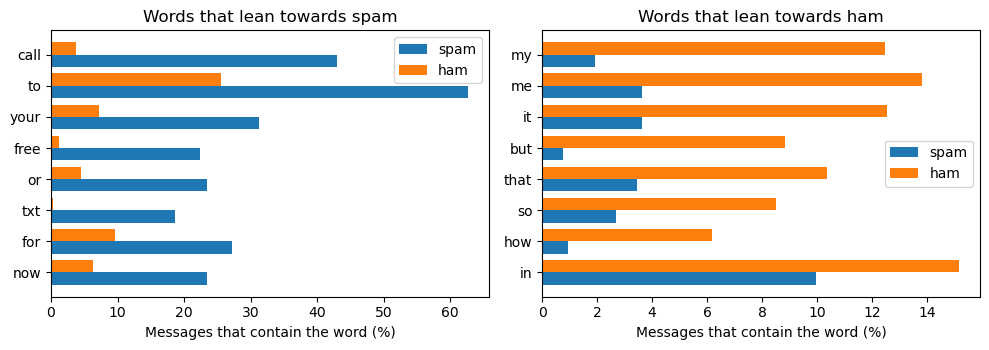

In [5]:
present = (counts > 0).astype(int)                    # 1 where the word occurs in the message at all
share = pd.DataFrame({
    "spam": np.asarray(present[y_train == 1].mean(axis=0)).ravel(),
    "ham": np.asarray(present[y_train == 0].mean(axis=0)).ravel(),
}, index=words)
share["difference"] = share["spam"] - share["ham"]
ordered = share.sort_values("difference")
print("share of messages that contain the word (%)")
print((100 * ordered.tail(8)[::-1]).round(1).to_string())
print((100 * ordered.head(8)).round(1).to_string())
common = (100 * share.loc[["you", "the", "and"], ["spam", "ham"]]).round(1)
print("\nnearly the same on both sides:", common.to_dict("index"))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, part, title in [(axes[0], ordered.tail(8), "Words that lean towards spam"),
                        (axes[1], ordered.head(8)[::-1], "Words that lean towards ham")]:
    places = np.arange(len(part))
    ax.barh(places, 100 * part["spam"], height=-0.4, align="edge", label="spam")
    ax.barh(places, 100 * part["ham"], height=0.4, align="edge", label="ham")
    ax.set_yticks(places, part.index)
    ax.set_xlabel("Messages that contain the word (%)")
    ax.set_title(title)
    ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "words_that_separate_spam_from_ham.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** <!-- figure: words_that_separate_spam_from_ham.png | Words that separate spam from ham | 5.2cm -->
`call` is in 42.9% of the spam and 3.7% of the ham, and `free`, `txt` and `now` tell the same story. On the other side are the words people write to people: `my`, `me`, `it`, `but`, `that`. Some entries deserve a second look. `to`, `or` and `for` lean towards spam partly because spam messages are nearly three times as long, so every common word has more room to occur. And `you`, `the` and `and` occur at similar rates on both sides: frequent, and useless for this task.

**Checkpoint: before you move on**

- 5,169 different messages, 12.6% spam; 4,135 to work on and 1,034 sealed.
- Your token rule matches `CountVectorizer`; the vocabulary has 7,680 tokens and 55% of them occur once.
- The table of counts is 0.17% full, and half of the test messages contain a token it has no column for.

## Part B — A spam filter

**Goal.** Build a filter inside a pipeline, weigh words with tf-idf, compare four filters, read what one of them learned, and choose a threshold that protects real messages.

*Questions 6–10 · Data: SMS spam collection*

### Question 6 — Fit naive Bayes inside a pipeline

Start with the baseline that costs nothing, and then the simplest real filter: naive Bayes on the counts. The vocabulary is learned from messages, so the vectorizer is a fitted step and belongs inside the pipeline, where every fold of the cross-validation fits it on its own training messages. Write two helpers that every filter in Part B will share.

**Read the code.**

- `cross_validated` builds a pipeline of two steps and calls `cross_val_predict`, which returns a prediction for every training message, each made by a pipeline fitted without that message. `method="predict_proba"` asks for probabilities, and `[:, 1]` keeps the probability of spam.
- `score` turns probabilities into decisions with `prob_spam >= threshold` and returns five numbers in a dictionary. `flagged & (y_train == 0)` marks real messages sent to the spam folder, and `~flagged & (y_train == 1)` marks spam let through.
- `average_precision_score` uses the probabilities themselves, so it does not depend on the threshold.
- `show` turns a list of such dictionaries into a table: one row for each filter, with the filter's name as the row label.
- The dictionary `prob` keeps each filter's probabilities under its name for the questions that follow.

In [6]:
folds = StratifiedKFold(5, shuffle=True, random_state=42)

def cross_validated(vectorizer, model):
    """A spam probability for every training message, each from a pipeline that never saw it."""
    pipeline = Pipeline([("words", vectorizer), ("model", model)])
    return cross_val_predict(pipeline, text_train, y_train, cv=folds, method="predict_proba")[:, 1]

def score(name, prob_spam, threshold=0.5):
    """Precision, recall and the two kinds of mistake at one threshold, on the training messages."""
    flagged = prob_spam >= threshold
    return {"filter": name,
            "precision": precision_score(y_train, flagged),
            "recall": recall_score(y_train, flagged),
            "average precision": average_precision_score(y_train, prob_spam),
            "real flagged": int((flagged & (y_train == 0)).sum()),
            "spam missed": int((~flagged & (y_train == 1)).sum())}

def show(rows):
    """Print a list of scores as a table, one filter per line."""
    print(pd.DataFrame(rows).set_index("filter").round(3).to_string())

print(f"answering 'ham' every time is right for {1 - y_train.mean():.1%} of the training messages\n")
prob = {"naive Bayes on counts": cross_validated(CountVectorizer(), MultinomialNB())}
show([score("naive Bayes on counts", prob["naive Bayes on counts"])])

answering 'ham' every time is right for 87.4% of the training messages

                       precision  recall  average precision  real flagged  spam missed
filter                                                                                
naive Bayes on counts      0.969   0.902              0.955            15           51


**What the output shows.** A filter that never flags anything is 87.4% accurate, which is why accuracy is not printed again in this part. Naive Bayes on plain counts flags 15 of the 3,613 real training messages and misses 51 of the 522 spam: a precision of 0.969 and a recall of 0.902 from a model that trains in a fraction of a second. This is the number the other filters have to beat.

### Question 7 — Weigh the words with tf-idf, by hand first

A count treats every word alike. Tf-idf multiplies each count by a weight that is larger for rarer words, and then scales every row to length 1. Work it out by hand on four tiny messages, check your numbers against `TfidfVectorizer`, and then look at the weights it gives to six real words.

**Read the code.**

- `(tiny_counts > 0).sum()` counts, for each word, the messages that contain it.
- `np.log((1 + len(tiny)) / (1 + in_messages)) + 1` is the idf formula that scikit-learn uses. `np.log` is the natural logarithm.
- `tiny_counts.loc[2] * idf` multiplies the counts of the third message by the idf of each word. Dividing by `np.sqrt((raw ** 2).sum())` scales the row to length 1.
- `weights[2]` is the same row as computed by `TfidfVectorizer`, stored sparse, so the dictionary is built from its `indices` and `data` as in Question 4.
- `real.idf_` holds one idf per word of the real vocabulary. Putting it in a Series indexed by the words lets you look words up by name.

In [7]:
tiny = ["win a free prize now", "call me now", "free call free prize", "are you free now"]
tiny_counter = CountVectorizer()
tiny_words = tiny_counter.fit(tiny).get_feature_names_out()
tiny_counts = pd.DataFrame(tiny_counter.transform(tiny).toarray(), columns=tiny_words)
print(tiny_counts.to_string())

in_messages = (tiny_counts > 0).sum()                              # messages that contain each word
idf = np.log((1 + len(tiny)) / (1 + in_messages)) + 1
raw = tiny_counts.loc[2] * idf                                     # message 3: count times idf ...
by_hand = raw / np.sqrt((raw ** 2).sum())                          # ... scaled to length 1
print("\nidf:", idf.round(3).to_dict())
print("message 3 by hand:           ", by_hand[by_hand > 0].round(3).to_dict())

weights = TfidfVectorizer().fit_transform(tiny)
print("message 3 by TfidfVectorizer:", {tiny_words[j]: round(float(v), 3)
                                        for j, v in sorted(zip(weights[2].indices, weights[2].data))})

# The same weights on the real training messages.
real = TfidfVectorizer().fit(text_train)
real_idf = pd.Series(real.idf_, index=real.get_feature_names_out())
chosen_words = ["you", "call", "free", "claim", "prize", "lunch"]
containing = {w: int(present[:, counter.vocabulary_[w]].sum()) for w in chosen_words}
print("\nmessages containing the word:", containing)
print("idf on the training messages:", real_idf[chosen_words].round(2).to_dict())

   are  call  free  me  now  prize  win  you
0    0     0     1   0    1      1    1    0
1    0     1     0   1    1      0    0    0
2    0     1     2   0    0      1    0    0
3    1     0     1   0    1      0    0    1

idf: {'are': 1.916, 'call': 1.511, 'free': 1.223, 'me': 1.916, 'now': 1.223, 'prize': 1.511, 'win': 1.916, 'you': 1.916}
message 3 by hand:            {'call': 0.465, 'free': 0.753, 'prize': 0.465}
message 3 by TfidfVectorizer: {'call': 0.465, 'free': 0.753, 'prize': 0.465}



messages containing the word: {'you': 1218, 'call': 358, 'free': 158, 'claim': 69, 'prize': 57, 'lunch': 29}
idf on the training messages: {'you': 2.22, 'call': 3.44, 'free': 4.26, 'claim': 5.08, 'prize': 5.27, 'lunch': 5.93}


**What the output shows.** `free` occurs in three of the four tiny messages and gets the smallest idf, 1.223. The words found in a single message get the largest, 1.916. In message 3 the repeated word `free` still weighs the most, 0.753, but less than its count of 2 alone would give it. Your numbers and scikit-learn's agree to the last digit. On the real messages, `you` is in 1,218 of them and gets an idf of 2.22, while `prize` is in 57 and gets 5.27. Notice `lunch`: it gets an even larger weight than `prize`, simply because it is rarer. The idf has never seen a label. Deciding which words point to spam is left to the classifier.

### Question 8 — Compare four filters

Three more candidates, each cross-validated the same way: a logistic regression on tf-idf with its default penalty, the same model with a weaker penalty, and a logistic regression that does not use words at all. The last one cuts every word into overlapping pieces of two to five characters, so that `txt` contributes `tx`, `xt`, `txt` and a few more.

**Read the code.**

- Each entry of `candidates` is a pair: a vectorizer and a model. The loop hands both to `cross_validated` and stores the probabilities in `prob`, which already holds those of naive Bayes. `show` then prints all four filters as one table.
- `C=10` weakens the penalty of the logistic regression: a larger `C` lets the weights grow further from zero.
- `analyzer="char_wb"` builds the columns from pieces of characters inside each word, and `ngram_range=(2, 5)` asks for pieces of two to five characters. `sublinear_tf=True` replaces a count c by 1 + ln c.
- `precision_recall_curve` returns the precision and the recall at every possible threshold, and the loop draws one curve per filter.
- `plt.xlim(0.6, 1)` and `plt.ylim(0.9, 1.003)` zoom in on the corner where the four curves differ.

                              precision  recall  average precision  real flagged  spam missed
filter                                                                                       
naive Bayes on counts             0.969   0.902              0.955            15           51
logistic on tf-idf, C = 1         0.992   0.738              0.966             3          137
logistic on tf-idf, C = 10        0.980   0.862              0.973             9           72
logistic on character pieces      0.996   0.895              0.985             2           55



columns of the character filter: 69650
the pieces of 'txt': [' t', 'tx', 'xt', 't ', ' tx', 'txt', 'xt ', ' txt', 'txt ', ' txt ']


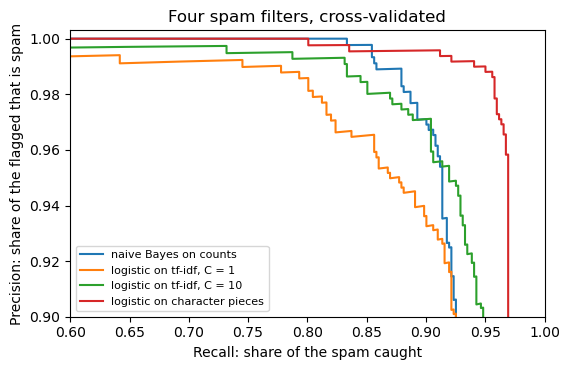

In [8]:
pieces = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)
candidates = {
    "logistic on tf-idf, C = 1": (TfidfVectorizer(), LogisticRegression(max_iter=2000)),
    "logistic on tf-idf, C = 10": (TfidfVectorizer(), LogisticRegression(max_iter=2000, C=10)),
    "logistic on character pieces": (pieces, LogisticRegression(max_iter=2000, C=10)),
}
for name, (vectorizer, model) in candidates.items():
    prob[name] = cross_validated(vectorizer, model)
show([score(name, prob_spam) for name, prob_spam in prob.items()])
print("\ncolumns of the character filter:", len(pieces.fit(text_train).vocabulary_))
print("the pieces of 'txt':", pieces.build_analyzer()("txt"))

plt.figure(figsize=(5.8, 3.8))
for name, prob_spam in prob.items():
    precision, recall, _ = precision_recall_curve(y_train, prob_spam)
    plt.plot(recall, precision, label=name)
plt.xlim(0.6, 1)
plt.ylim(0.9, 1.003)
plt.xlabel("Recall: share of the spam caught")
plt.ylabel("Precision: share of the flagged that is spam")
plt.title("Four spam filters, cross-validated")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "four_spam_filters.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** <!-- figure: four_spam_filters.png | Four spam filters, cross-validated | 6cm -->
With the default penalty the logistic regression is too timid: it flags only 3 real messages but misses 137 spam. With thousands of columns and a few non-zero cells in each row, `C = 1` holds the weights too close to zero. `C = 10` halves the misses. Now compare ranking with deciding. The logistic regression with `C = 10` has a higher average precision than naive Bayes, 0.973 against 0.955: over the whole range of thresholds it orders the messages better. On the chart its curve crosses that of naive Bayes near a recall of 0.9 and holds up beyond it, where the curve of naive Bayes drops away. And yet at the threshold of 0.5 it catches less spam. The threshold is a separate decision, and Question 10 makes it. The character filter is best on every count: 2 real messages flagged, 55 spam missed, and its curve lies above the others. Spam is full of shortened words, codes and prices, and a word the filter has never seen still shares most of its pieces with words it has.

### Question 9 — Read what the filter learned

A linear model on words can be read. Fit the word-based logistic regression on all the training messages and list the words with the largest weights in each direction. Then follow up anything that looks strange.

**Read the code.**

- `word_filter.named_steps["model"].coef_[0]` is one weight for every column, and `get_feature_names_out()` gives the word of each column. Together they make a Series that `sort_values()` orders from the most ham-like word to the most spam-like.
- `weight.tail(10).index[::-1]` takes the ten largest weights and reverses them, so that the largest comes first.
- `text_train.str.contains("&lt;", regex=False)` marks the messages that contain those four characters. `regex=False` means the text is searched for as it is written, not as a pattern.
- `y_train[coded]` selects the labels of the marked messages.
- `nsmallest(3)` picks the three shortest of them to print.

In [9]:
word_filter = Pipeline([("words", TfidfVectorizer()), ("model", LogisticRegression(max_iter=2000, C=10))])
word_filter.fit(text_train, y_train)
weight = pd.Series(word_filter.named_steps["model"].coef_[0],
                   index=word_filter.named_steps["words"].get_feature_names_out()).sort_values()
print("pushing towards spam:", weight.tail(10).index[::-1].tolist())
print("pushing towards ham: ", weight.head(10).index.tolist())

# Two of the ham words are not words. Where do they come from?
coded = text_train.str.contains("&lt;", regex=False).to_numpy()
print("\ntraining messages that contain '&lt;':", int(coded.sum()),
      " of them spam:", int(y_train[coded].sum()))
for i in text_train[coded].str.len().nsmallest(3).index:
    print("   ", text_train[i])

pushing towards spam: ['txt', 'text', 'reply', 'call', 'uk', 'chat', 'stop', 'www', '50', '150p']
pushing towards ham:  ['my', 'me', 'gt', 'can', 'lt', 'that', 'ok', 'at', 'da', 'but']

training messages that contain '&lt;': 179  of them spam: 0
    Wait  &lt;#&gt;  min..
    Just got to  &lt;#&gt;
    No probably  &lt;#&gt; %.


**What the output shows.** The spam side reads as you would expect: `txt`, `text`, `reply`, `call`, `uk`, `chat`, `stop`, `www`. The ham side holds two strangers, `gt` and `lt`. They are what the tokenizer leaves of `&gt;` and `&lt;`, the codes that web pages use for the signs > and <. In this collection, numbers and other details in some ham messages were replaced by placeholders such as `&lt;#&gt;`, and 179 real training messages contain one against no spam message at all. The filter is right to use that on this dataset, and it would be wrong on a real phone, where no message contains `&lt;`. The pattern describes how the data was collected. Reading the largest weights is the cheapest check there is for text.

### Question 10 — Choose the threshold, then open the test messages

The two mistakes do not cost the same. Spam in the inbox is a nuisance, and a real message in the spam folder may be a missed appointment. Suppose the rule is that at most one real message in a thousand may be sent to the spam folder. Find the threshold that meets it on the cross-validated probabilities of the character filter. Only then fit the filter on all the training messages and open the test messages, once.

**Read the code.**

- In `strict_threshold`, `np.sort(prob_spam[y == 0])[::-1]` lists the probabilities of the real messages from the most spam-like down. `budget` is how many of them may be flagged, and the threshold is set just above the first one that may not be.
- `spam_filter` is the chosen pipeline, fitted on all the training messages. `predict_proba(text_test)[:, 1]` is the first and only use of the test messages in this part.
- `confusion_matrix(y_test, flagged)` counts the four outcomes. Its rows are the truth and its columns the decision.
- The loop prints the real messages that were sent to the spam folder, cut to 100 characters.

In [10]:
def strict_threshold(y, prob_spam, allowed=0.001):
    """The lowest threshold that sends at most `allowed` of the real messages to the spam folder."""
    ham = np.sort(prob_spam[y == 0])[::-1]                  # real messages, most spam-like first
    budget = int(allowed * len(ham))                        # how many of them may be flagged
    return float(ham[budget]) + 1e-6                        # just above the first that may not be

chosen = "logistic on character pieces"
threshold = strict_threshold(y_train, prob[chosen])
print(f"threshold for at most 1 real message in 1,000: {threshold:.2f}")
show([score("cross-validated, at 0.50", prob[chosen]),
      score(f"cross-validated, at {threshold:.2f}", prob[chosen], threshold)])

# Fit the chosen filter on all the training messages, and open the test messages once.
vectorizer, model = candidates[chosen]
spam_filter = Pipeline([("words", vectorizer), ("model", model)]).fit(text_train, y_train)
test_prob = spam_filter.predict_proba(text_test)[:, 1]
flagged = test_prob >= threshold
matrix = confusion_matrix(y_test, flagged)
outcome = pd.DataFrame(matrix, index=["real", "spam"], columns=["to the inbox", "to the spam folder"])
print("\n" + outcome.to_string())
print(f"test precision {precision_score(y_test, flagged):.3f}   recall {recall_score(y_test, flagged):.3f}"
      f"   average precision {average_precision_score(y_test, test_prob):.3f}")
print("real messages sent to the spam folder:")
for message in text_test[flagged & (y_test == 0)]:
    print("   ", message[:100])

threshold for at most 1 real message in 1,000: 0.37
                          precision  recall  average precision  real flagged  spam missed
filter                                                                                   
cross-validated, at 0.50      0.996   0.895              0.985             2           55
cross-validated, at 0.37      0.994   0.921              0.985             3           41



      to the inbox  to the spam folder
real           900                   3
spam             9                 122
test precision 0.976   recall 0.931   average precision 0.991
real messages sent to the spam folder:
    Your daily text from me – a favour this time
    Glad to see your reply.
    I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phoneboo


**What the output shows.** The threshold comes out at 0.37, which is below 0.5. At 0.5 the filter flagged only 2 real training messages and the rule allows 3, so the threshold can come down, and the recall rises from 0.895 to 0.921. On the test messages the filter catches 122 of the 131 spam, a recall of 0.931 with a precision of 0.976. Now read the top row of the table. The rule said one real message in a thousand, and the test shows 3 in 903. That is not a contradiction: the threshold was fixed by the three most spam-like real messages among 3,613, and a rate that rests on three messages is very uncertain. Read the three flagged messages too. The third is an automatic invitation from a website that offers "FREE SMS". It is labeled ham, and many readers would call it spam. Labels are made by people, and some of a model's mistakes are disagreements with them.

**Checkpoint: before you move on**

- Naive Bayes on counts: precision 0.969 and recall 0.902 at a threshold of 0.5.
- The character filter is best: average precision 0.985, against 0.973 for words with `C = 10`.
- `gt` and `lt` among the ham words come from placeholders in 179 real messages.
- Threshold 0.37; on the test: 122 of 131 spam caught, 3 of 903 real messages flagged.

## Part C — Seventy-seven intents

**Goal.** Use the same pipeline on a harder problem with 77 classes, find the intents it confuses, test three preprocessing choices, and search the stored questions by similarity.

*Questions 11–14 · Data: Banking77*

### Question 11 — Classify bank questions into 77 intents

The second collection holds questions typed to a bank's support chat. Each one belongs to one of 77 intents, such as `card_arrival` or `change_pin`, and the file carries its own split into training and test questions. Read it, look at a few questions, and fit the pipeline of Part B: tf-idf on words and a logistic regression. With many classes, report two numbers: how often the model's first answer is right, and how often the right answer is among its top three.

**Read the code.**

- `bank[bank["split"] == "train"]` keeps the rows of the official training set. `reset_index(drop=True)` renumbers them from 0, so that row positions and row labels agree.
- `drop_duplicates("label").sort_values("label")["intent"].tolist()` keeps one row per label, in label order, and reads off the names. Position 0 of the list is the name of label 0.
- `train["intent"].value_counts()` counts the questions of each intent, and `idxmin()` and `idxmax()` name the smallest and the largest.
- `train.sample(4, random_state=1).iterrows()` walks through four randomly chosen rows, and the loop prints the intent and the first 76 characters of each question.
- `intent_model.predict_proba(q_test)` gives 77 probabilities for each test question. `argmax(axis=1)` is the position of the largest, which is the predicted label.
- `np.argsort(intent_prob, axis=1)[:, -3:]` gives the positions of the three largest probabilities in each row. The list comprehension checks, question by question, whether the true label is among them.

In [11]:
bank = pd.read_csv(DATA / "advanced/banking77/banking77.csv")
train = bank[bank["split"] == "train"].reset_index(drop=True)
test = bank[bank["split"] == "test"].reset_index(drop=True)
intents = bank.drop_duplicates("label").sort_values("label")["intent"].tolist()   # position = label
q_train, q_test = train["text"], test["text"]
i_train, i_test = train["label"].to_numpy(), test["label"].to_numpy()
sizes = train["intent"].value_counts()
print(len(q_train), "training questions,", len(q_test), "test questions,", len(intents), "intents")
print(f"training questions per intent: from {sizes.min()} ({sizes.idxmin()})"
      f" to {sizes.max()} ({sizes.idxmax()})")
for _, question in train.sample(4, random_state=1).iterrows():
    print(f"    {question['intent']:26s} {question['text'][:76]}")

intent_model = Pipeline([("words", TfidfVectorizer()), ("model", LogisticRegression(max_iter=3000, C=10))])
intent_model.fit(q_train, i_train)
intent_prob = intent_model.predict_proba(q_test)
predicted = intent_prob.argmax(axis=1)
intent_accuracy = (predicted == i_test).mean()
top_three = np.argsort(intent_prob, axis=1)[:, -3:]
in_top_three = np.mean([truth in row for truth, row in zip(i_test, top_three)])
columns = len(intent_model.named_steps["words"].vocabulary_)
print(f"\ncolumns: {columns}   guessing: {1 / len(intents):.3f}")
print(f"test accuracy: {intent_accuracy:.3f}   right intent in the top three: {in_top_three:.3f}")

10003 training questions, 3080 test questions, 77 intents
training questions per intent: from 35 (contactless_not_working) to 187 (card_payment_fee_charged)
    getting_spare_card         I need more physical cards.
    lost_or_stolen_card        Someone stole my wallet with my card in it while vacationing in Spain. I rea
    transaction_charged_twice  I was charged for the same thing twice
    pending_card_payment       I made a purchase earlier today but it is still listed as pending- when will



columns: 2320   guessing: 0.013
test accuracy: 0.900   right intent in the top three: 0.970


**What the output shows.** 10,003 questions to train on and 3,080 to test on, in 77 intents with between 35 and 187 training questions each. The questions are short and many differ by a word or two. A model that only weighs 2,320 words sends nine test questions in ten to the right one of 77 intents: an accuracy of 0.900, where guessing would score 0.013. The right intent is among its three most likely for 97.0% of the questions. That second number matters for design: a support screen that offers three suggestions would be right far more often than one that offers a single answer, with the same model.

### Question 12 — Find where the classifier fails

One accuracy figure for 77 classes hides most of the story. Compute the recall of every intent, and list the pairs of intents that are confused most often.

**Read the code.**

- `confusion_matrix(i_test, predicted)` is a table of 77 rows by 77 columns: the row is the true intent and the column the predicted one.
- `matrix77.diagonal()` holds the questions that were classified correctly, and `matrix77.sum(axis=1)` the number of test questions of each intent. Their ratio is the recall of each intent.
- `matrix77 - np.diag(matrix77.diagonal())` sets the diagonal to zero, which leaves only the mistakes.
- `np.where(mistakes >= 4)` returns the rows and the columns of the cells that hold four or more mistakes, and `zip(*...)` pairs them up.
- The bar chart draws the 77 recalls in increasing order.

lowest recall:
virtual_card_not_working                   0.675
fiat_currency_support                      0.750
pending_transfer                           0.750
balance_not_updated_after_bank_transfer    0.750
card_acceptance                            0.800
intents with every test question right: 9   intents below 0.80: 4

pairs confused four times or more:
                            asked_about                     model_answered  times
balance_not_updated_after_bank_transfer transfer_not_received_by_recipient      5
                     verify_my_identity                why_verify_identity      5
               virtual_card_not_working        get_disposable_virtual_card      5
                        card_acceptance                   card_not_working      4
                           card_arrival             card_delivery_estimate      4
                  fiat_currency_support                   exchange_via_app      4
                         pending_top_up                      top

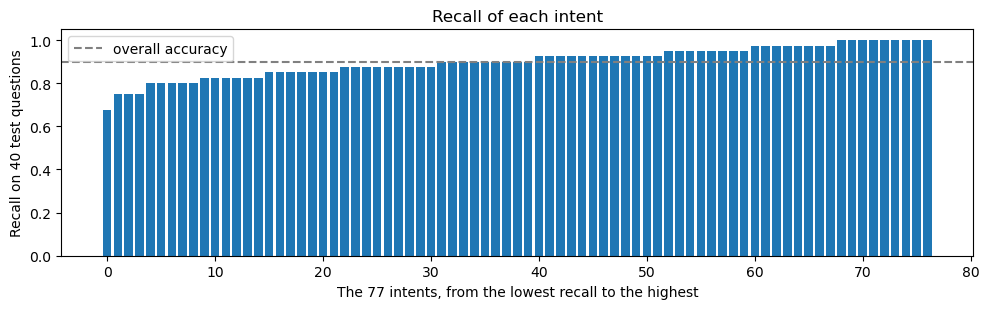

In [12]:
matrix77 = confusion_matrix(i_test, predicted)
recall = pd.Series(matrix77.diagonal() / matrix77.sum(axis=1), index=intents).sort_values()
print("lowest recall:")
print(recall.head(5).round(3).to_string())
print("intents with every test question right:", int((recall == 1).sum()),
      "  intents below 0.80:", int((recall < 0.80).sum()))

mistakes = matrix77 - np.diag(matrix77.diagonal())
pairs = [(intents[i], intents[j], int(mistakes[i, j])) for i, j in zip(*np.where(mistakes >= 4))]
confused = pd.DataFrame(pairs, columns=["asked_about", "model_answered", "times"])
confused = confused.sort_values(["times", "asked_about"], ascending=[False, True])
print("\npairs confused four times or more:")
print(confused.to_string(index=False))

plt.figure(figsize=(10, 3.2))
plt.bar(range(len(recall)), recall.to_numpy())
plt.axhline(intent_accuracy, linestyle="--", color="grey", label="overall accuracy")
plt.xlabel("The 77 intents, from the lowest recall to the highest")
plt.ylabel("Recall on 40 test questions")
plt.title("Recall of each intent")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "recall_of_each_intent.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** <!-- figure: recall_of_each_intent.png | Recall of each intent | 4.4cm -->
The chart shows how uneven a 90% accuracy is. Nine intents have all 40 of their test questions right, and four fall below 0.80. The weakest is `virtual_card_not_working`, at 0.675: 27 of its 40 questions. The confused pairs explain why. `virtual_card_not_working` is read as `get_disposable_virtual_card`, `verify_my_identity` as `why_verify_identity`, and a bank transfer that has not shown up as a transfer the recipient has not received. In each pair the two intents use almost the same words, and a person might hesitate too. A list like this is what you take back to the people who defined the intents.

### Question 13 — Validate the preprocessing

Removing stop words and adding word pairs are often applied without checking. Check them. Score three vectorizers by three-fold cross-validation on the training questions, with the same model each time.

**Read the code.**

- `stop_words="english"` deletes scikit-learn's list of very common English words before counting.
- `ngram_range=(1, 2)` makes a column for every single word and every pair of neighbouring words, and `min_df=2` keeps only the columns found in at least two questions.
- `cross_val_score(...)` returns the accuracy of each of the three folds, and `.mean()` averages them. Accuracy is the default score for a classifier.
- `len(candidate.fit(q_train).vocabulary_)` is the number of columns the vectorizer makes from the training questions.
- `get_stop_words()` returns the stop list, and the last line checks which of eight words are on it.

In [13]:
settings = {
    "single words": TfidfVectorizer(),
    "single words, stop words removed": TfidfVectorizer(stop_words="english"),
    "words and pairs": TfidfVectorizer(ngram_range=(1, 2), min_df=2),
}
three_folds = StratifiedKFold(3, shuffle=True, random_state=42)
preprocessing = {}
for name, candidate in settings.items():
    pipeline = Pipeline([("words", candidate), ("model", LogisticRegression(max_iter=3000, C=10))])
    cv_accuracy = cross_val_score(pipeline, q_train, i_train, cv=three_folds).mean()
    columns = len(candidate.fit(q_train).vocabulary_)
    preprocessing[name] = {"columns": columns, "cv_accuracy": cv_accuracy}
    print(f"{name:34s} {columns:6d} columns   cross-validated accuracy {cv_accuracy:.3f}")

stop_list = TfidfVectorizer(stop_words="english").get_stop_words()
asked = ["how", "why", "not", "my", "when", "still", "card", "pin"]
print("\non the stop list:", [word for word in asked if word in stop_list])

single words                         2320 columns   cross-validated accuracy 0.876


single words, stop words removed     2097 columns   cross-validated accuracy 0.829


words and pairs                     10292 columns   cross-validated accuracy 0.867

on the stop list: ['how', 'why', 'not', 'my', 'when', 'still']


**What the output shows.** Plain single words win. Removing stop words costs almost five points of accuracy, from 0.876 to 0.829. The last line shows why: `how`, `why`, `not`, `my`, `when` and `still` are all on the stop list, and in this task they are the difference between "how do I verify my identity" and "why do I have to verify my identity". Word pairs do not help either: four times the columns for a slightly lower score. Neither result is a law. On the text messages of Part B, removing stop words helped naive Bayes a little. Each choice is a setting, and the only way to know is to run it.

### Question 14 — Search the stored questions by similarity

A table of tf-idf rows is also a search index. Every row has length 1, so multiplying the table by the row of a new question gives the cosine similarity between that question and every stored one. Write the search, and try it on three questions.

**Read the code.**

- `intent_model.named_steps["words"]` is the fitted vectorizer of Question 11, and `transform(q_train)` gives one tf-idf row for each stored question.
- `vectorizer.transform([query])` is the row of the new question. `.T` turns it into a column, and `w_train @ ...` multiplies every stored row by it: one similarity for each stored question.
- `.toarray().ravel()` turns the sparse result into a plain array.
- `np.argsort(similarity)[::-1][:k]` gives the positions of the `k` largest similarities, largest first.

In [14]:
vectorizer = intent_model.named_steps["words"]
w_train = vectorizer.transform(q_train)               # one tf-idf row per stored question, of length 1

def nearest_by_words(query, k=3):
    """Print the k stored questions most similar to the query, by the cosine of their tf-idf rows."""
    similarity = (w_train @ vectorizer.transform([query]).T).toarray().ravel()
    for i in np.argsort(similarity)[::-1][:k]:
        print(f"    {similarity[i]:.2f}  {train['intent'][i]:36s} {q_train[i]}")

queries = ["how do I change my pin", "my new card still has not arrived",
           "the cash machine swallowed my card"]
for query in queries:
    print("query:", query)
    nearest_by_words(query)

query: how do I change my pin
    0.96  change_pin                           How do I change my card PIN?
    0.94  change_pin                           How do I change the PIN?
    0.86  change_pin                           Change my pin?
query: my new card still has not arrived
    0.73  transfer_not_received_by_recipient   My transfer has not arrived.
    0.66  card_arrival                         Why has my new card still not come?
    0.62  transfer_not_received_by_recipient   Why has my transfer not arrived yet?
query: the cash machine swallowed my card
    0.61  card_swallowed                       How do I get a new card as your machine swallowed mine!
    0.55  card_swallowed                       What do I do if the ATM swallowed my card?
    0.55  card_swallowed                       An ATM swallowed my credit card!


**What the output shows.** The first search is easy: three stored questions about changing a PIN, with similarities up to 0.96. The second goes wrong. The nearest stored question is about a transfer, because it shares `my`, `has`, `not` and `arrived` with the query. The stored question that asks the same thing says "come" where the query says "arrived", and to a bag of words those are two columns with nothing in common. The third search finds the right intent, but only weakly, at 0.61: it can match `machine`, `swallowed` and `card`, but it has no way to know that a cash machine is an ATM. Counting matches words letter for letter. Part D is about that limit.

**Checkpoint: before you move on**

- 77 intents: test accuracy 0.900, and the right intent is in the top three for 97.0% of questions.
- Nine intents are perfect; `virtual_card_not_working` is the weakest, at 0.675.
- Removing stop words costs almost five points here, and word pairs do not help.
- The search for "my new card still has not arrived" returns a question about a transfer first.

## Part D — Word vectors

**Goal.** Learn a vector for every word from nothing but which words appear near which, then use the vectors to search and to classify, and find out when they beat counting.

*Questions 15–18 · Data: Banking77*

### Question 15 — Count the company each word keeps

Words that can stand in for each other turn up among the same neighbours. To use that, count for every pair of words how often one occurs within four positions of the other, over all the training questions. Then look at the company of one word, `declined`, twice: by raw count, and by how many times more often than chance the pair occurs.

**Read the code.**

- `documents` holds the tokens of every training question. `Counter` counts them, and `vocabulary` keeps the words that occur at least three times, in alphabetical order. `position` maps each word to its row number. The loop variable is called `tokens_`, with an underscore, so that it does not replace the function `tokens` of Question 3.
- For each question, `ids` is its words as row numbers. For the word at place `here`, `ids[max(0, here - window):here]` are up to four words before it and `ids[here + 1:here + 1 + window]` up to four words after it. Each such pair adds one entry to `rows` and `cols`.
- `sparse.coo_matrix((ones, (rows, cols)), shape=...)` builds a sparse table from those entries, and `.tocsr()` adds up the entries that fall in the same cell.
- `together[position["declined"]]` is the row of `declined`: how often each word occurred near it.
- `expected` is how often each word would occur near `declined` if words were scattered at random: the product of the two row totals, divided by the grand total. Dividing the real count by it gives the `lift`.
- `company[company["count"] >= 5]` keeps the words seen near `declined` at least five times, so that a single chance meeting cannot top the second list.

In [15]:
analyze = vectorizer.build_analyzer()
documents = [analyze(text) for text in q_train]
frequency = Counter(word for tokens_ in documents for word in tokens_)
vocabulary = sorted(word for word, n in frequency.items() if n >= 3)
position = {word: i for i, word in enumerate(vocabulary)}

window = 4
rows, cols = [], []
for tokens_ in documents:
    ids = [position[word] for word in tokens_ if word in position]
    for here, word_id in enumerate(ids):
        for neighbor in ids[max(0, here - window):here] + ids[here + 1:here + 1 + window]:
            rows.append(word_id)
            cols.append(neighbor)
shape = (len(vocabulary), len(vocabulary))
together = sparse.coo_matrix((np.ones(len(rows)), (rows, cols)), shape=shape).tocsr()
print("words with a row:", len(vocabulary), "  pairs counted:", len(rows),
      "  cells not zero:", together.nnz)

# The company of one word, by raw count and by how many times more often than chance.
alone = np.asarray(together.sum(axis=1)).ravel()                 # how much company each word has in total
near = together[position["declined"]].toarray().ravel()
expected = alone[position["declined"]] * alone / alone.sum()
company = pd.DataFrame({"count": near, "lift": near / expected}, index=vocabulary)
most_often = company["count"].sort_values(ascending=False).head(8).astype(int)
print("\nmost often near 'declined':", most_often.to_dict())
often = company[company["count"] >= 5]                           # seen near it at least five times
above_chance = often["lift"].sort_values(ascending=False).head(8).round(1)
print("furthest above chance:     ", above_chance.to_dict())

words with a row: 1210   pairs counted: 650428   cells not zero: 105983

most often near 'declined': {'my': 147, 'was': 140, 'card': 106, 'it': 77, 'why': 58, 'and': 51, 'payment': 50, 'the': 49}
furthest above chance:      {'clearly': 47.6, 'kept': 33.8, 'keeps': 18.3, 'getting': 14.0, 'suddenly': 11.8, 'try': 11.4, 'again': 11.1, 'being': 10.6}


**What the output shows.** 1,210 words occur at least three times, and the sliding window counted 650,428 pairs. Read the two lists for `declined`. By raw count its closest company is `my`, `was`, `card`, `it` and `why`: mostly words that are near everything, because they are everywhere. Compared with chance, the list changes character: `kept`, `keeps`, `getting`, `suddenly`, `again`. These are the words of someone whose card keeps getting declined, and the filler has dropped out. The word at the very top, `clearly`, is a warning as well: a word that is rare everywhere reaches a large ratio from a handful of sightings. This is why the next question takes the logarithm of the lift, which tames such ratios, and then compresses the table, which pools the evidence of many neighbours.

### Question 16 — Compress the company into word vectors

Each word now has a row of 1,210 numbers saying whose company it keeps. Take the logarithm of the lift, keep the pairs for which it is positive, and compress every row to 100 numbers with an SVD, the tool behind PCA in Lab 4. Those 100 numbers are the word's vector. Then ask each of seven words for its nearest neighbours.

**Read the code.**

- `together.tocoo()` exposes the table as three arrays: `row`, `col` and `data`, one entry for each cell that is not zero.
- `np.log(pairs.data * pairs.sum() / (alone[pairs.row] * alone[pairs.col]))` is the logarithm of the lift of every cell: the pointwise mutual information.
- `keep = pmi > 0` marks the pairs seen more often than chance, and a new sparse table is built from those alone.
- `TruncatedSVD(n_components=100, random_state=42).fit_transform(ppmi)` compresses each row to 100 numbers, and `normalize` scales every vector to length 1, so that a dot product of two vectors is their cosine similarity.
- In `neighbors`, `vectors @ vectors[position[word]]` is the similarity of every word to the given one. `[1:k + 1]` skips the first match, which is the word itself.

In [16]:
pairs = together.tocoo()
pmi = np.log(pairs.data * pairs.sum() / (alone[pairs.row] * alone[pairs.col]))
keep = pmi > 0                                                    # pairs seen more often than chance
ppmi = sparse.coo_matrix((pmi[keep], (pairs.row[keep], pairs.col[keep])), shape=shape).tocsr()
vectors = normalize(TruncatedSVD(n_components=100, random_state=42).fit_transform(ppmi))
print("cells above chance:", ppmi.nnz, "  word vectors:", vectors.shape)

def neighbors(word, k=5):
    """The k words whose vectors point most nearly the same way as the given word's."""
    similarity = vectors @ vectors[position[word]]
    return [vocabulary[i] for i in np.argsort(similarity)[::-1][1:k + 1]]

asked = ["pin", "stolen", "fee", "declined", "cash", "atm", "arrived"]
word_neighbors = {word: neighbors(word) for word in asked}
for word, near_words in word_neighbors.items():
    print(f"{word:9s}", near_words)

cells above chance: 77960   word vectors: (1210, 100)
pin       ['locked', 'blocked', 'entered', 'tries', 'unblock']
stolen    ['phone', 'lost', 'stole', 'smart', 'bag']
fee       ['extra', 'charged', 'charge', 'when', 'there']
declined  ['rejected', 'getting', 'keeps', 'today', 'declining']
cash      ['atm', 'withdrawal', 'amount', 'some', 'less']
atm       ['cash', 'machine', 'at', 'withdraw', 'the']
arrived   ['cleared', 'hasn', 'reached', 'she', 'shown']


**What the output shows.** Each of the 1,210 words is now a point in 100 dimensions. Nobody told the program that `declined` and `rejected` mean the same, that `stolen` goes with `lost` and `stole`, that a `fee` is something `charged`, or that `cash` comes out of an `atm`. It found all of that in ten thousand short questions by counting neighbours, with no labels at all. The lists also show what the method does not do. The neighbours of `pin` are `locked`, `blocked` and `tries`: words from the same situation, and none of them a synonym. Company measures what goes together as well as what means the same. And with so little text a few filler words, such as `the` and `when`, get in.

### Question 17 — Search again, by meaning

Give every question a vector too: the average of the vectors of its words, scaled to length 1. Then repeat the three searches of Question 14, comparing these averages in place of the tf-idf rows.

**Read the code.**

- `message_vectors` starts from a table of zeros with one row for each text. For each text it looks up the row numbers of its words, skipping any word that has no vector, and writes the average of their vectors into the row.
- `vectors[ids].mean(axis=0)` averages the chosen word vectors, column by column.
- `normalize(out)` scales each row to length 1, so that `d_train @ query_vector` is again a cosine similarity.
- `message_vectors([query])[0]` is the vector of one new question.

In [17]:
def message_vectors(texts):
    """Each text as the average of its words' vectors, scaled to length 1."""
    out = np.zeros((len(texts), vectors.shape[1]))
    for row, text in enumerate(texts):
        ids = [position[word] for word in analyze(text) if word in position]
        if ids:
            out[row] = vectors[ids].mean(axis=0)
    return normalize(out)

d_train, d_test = message_vectors(q_train), message_vectors(q_test)
print("one vector per question:", d_train.shape)

def nearest_by_vectors(query, k=3):
    """Print the k stored questions whose averaged word vectors are closest to the query's."""
    similarity = d_train @ message_vectors([query])[0]
    for i in np.argsort(similarity)[::-1][:k]:
        print(f"    {similarity[i]:.2f}  {train['intent'][i]:36s} {q_train[i]}")

for query in queries:
    print("query:", query)
    nearest_by_vectors(query)

one vector per question: (10003, 100)
query: how do I change my pin
    0.98  change_pin                           How do I change my card PIN?
    0.97  change_pin                           How do I change my PIN abroad?
    0.97  passcode_forgotten                   How do I change my passcode?
query: my new card still has not arrived
    0.96  card_arrival                         Why has my new card still not come?
    0.93  card_arrival                         My card still hasn't been delivered
    0.93  card_arrival                         My card hasn't arrived.
query: the cash machine swallowed my card
    0.95  card_swallowed                       The ATM machine ate my card.
    0.92  card_swallowed                       My card is stuck inside the ATM.
    0.92  card_swallowed                       The ATM took my card.


**What the output shows.** The search that went wrong is repaired. All three answers to "my new card still has not arrived" are now about a card that has not come, and the transfer is gone. For "the cash machine swallowed my card" the best match is "The ATM machine ate my card.", at 0.95, where the tf-idf search reached 0.61: the vectors match `cash machine` with `ATM` and `swallowed` with `ate`. Read the first search as well. Its third answer has the intent `passcode_forgotten`, "How do I change my passcode?". To these vectors a PIN and a passcode are nearly the same thing, which is true of the words and wrong for the bank, where they are two different intents. Blurring words together is what makes this search good, and the next question shows what it costs.

### Question 18 — Classify with the vectors, with many labels and with few

Do the averaged vectors classify better than tf-idf? Train the same logistic regression on each, first with every label, and then with only 2, 5 or 10 labeled questions for each intent. The word vectors themselves were built from all 10,003 questions without any labels, so with few labels they bring knowledge that the labeled questions alone cannot supply. A draw of two questions per intent is a matter of luck, so each small case is repeated with ten different draws.

**Read the code.**

- `accuracy_of(features_train, features_test, chosen)` fits the model on the chosen training rows and scores it on all the test questions. `slice(None)` stands for "every row". The first two calls use every label.
- `np.where(i_train == c)[0]` lists the rows of intent `c`, and `rng.choice(..., per_intent, replace=False)` draws that many different rows from it. `np.concatenate` joins the draws for the 77 intents.
- `np.random.default_rng(seed)` makes each of the ten draws repeatable.
- `label_efficiency` collects one row per case: the mean accuracy of each representation, and in how many of the ten draws the vectors came out ahead.

all the labels: tf-idf, 2,320 columns               test accuracy 0.900
all the labels: averaged word vectors, 100 columns  test accuracy 0.840


 2 labels per intent: tf-idf 0.413   word vectors 0.443   vectors ahead in 10 of 10 draws


 5 labels per intent: tf-idf 0.595   word vectors 0.586   vectors ahead in 1 of 10 draws


10 labels per intent: tf-idf 0.706   word vectors 0.679   vectors ahead in 0 of 10 draws


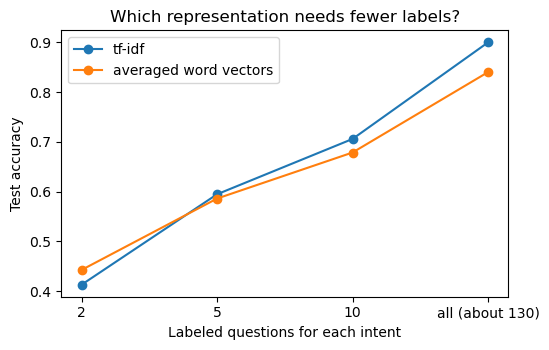

In [18]:
def accuracy_of(features_train, features_test, chosen=slice(None)):
    """Fit the logistic regression on the chosen training rows and score it on every test question."""
    model = LogisticRegression(max_iter=3000, C=10).fit(features_train[chosen], i_train[chosen])
    return (model.predict(features_test) == i_test).mean()

w_test = vectorizer.transform(q_test)
words_all, vectors_all = accuracy_of(w_train, w_test), accuracy_of(d_train, d_test)
print(f"all the labels: tf-idf, 2,320 columns               test accuracy {words_all:.3f}")
print(f"all the labels: averaged word vectors, 100 columns  test accuracy {vectors_all:.3f}")

label_efficiency = []
for per_intent in (2, 5, 10):
    by_words, by_vectors = [], []
    for seed in range(10):
        rng = np.random.default_rng(seed)
        few = np.concatenate([rng.choice(np.where(i_train == c)[0], per_intent, replace=False)
                              for c in range(len(intents))])
        by_words.append(accuracy_of(w_train, w_test, few))
        by_vectors.append(accuracy_of(d_train, d_test, few))
    ahead = int(np.sum(np.array(by_vectors) > np.array(by_words)))
    label_efficiency.append({"labels_per_intent": per_intent, "tfidf": np.mean(by_words),
                             "word_vectors": np.mean(by_vectors), "vectors_ahead_in_10": ahead})
    print(f"{per_intent:2d} labels per intent: tf-idf {np.mean(by_words):.3f}"
          f"   word vectors {np.mean(by_vectors):.3f}   vectors ahead in {ahead} of 10 draws")

curve = pd.DataFrame(label_efficiency)
plt.figure(figsize=(5.6, 3.6))
plt.plot(range(4), list(curve["tfidf"]) + [words_all], marker="o", label="tf-idf")
plt.plot(range(4), list(curve["word_vectors"]) + [vectors_all], marker="o", label="averaged word vectors")
plt.xticks(range(4), ["2", "5", "10", "all (about 130)"])
plt.xlabel("Labeled questions for each intent")
plt.ylabel("Test accuracy")
plt.title("Which representation needs fewer labels?")
plt.legend()
plt.tight_layout()
plt.savefig(RESULTS / "which_representation_needs_fewer_labels.png", dpi=160, bbox_inches="tight")
plt.show()

**What the output shows.** <!-- figure: which_representation_needs_fewer_labels.png | Which representation needs fewer labels? | 5.6cm -->
With every label, counting wins: 0.900 for tf-idf against 0.840 for the averaged vectors. Seventy-seven fine-grained intents are told apart by exact words, and an average blurs exactly those, as the PIN and the passcode of Question 17 showed. With about 130 labeled questions for each intent, the classifier can learn what every single word is worth. Take the labels away and the order turns round. With two labeled questions for each intent, the vectors lead in all ten draws, 0.443 against 0.413. A classifier on sparse columns then knows only the words that happen to occur in those two questions, while the vectors let it use a word it has never seen labeled, as long as that word lies near one it has. From five labels on, tf-idf is ahead again and the gap widens. Unlabeled text is worth the most when labels are fewest.

**Checkpoint: before you move on**

- 1,210 words have a vector of 100 numbers, learned without labels; `declined` sits next to `rejected`.
- Search by vectors puts three `card_arrival` questions first for the query that tf-idf got wrong.
- With all the labels: tf-idf 0.900, averaged vectors 0.840. With two labels per intent: 0.413 against 0.443.

## Finish — Save the model and the evidence, then try it yourself

**Goal.** Save the intent classifier with a card that says how to use it, write the results folder, and then test two more ideas yourself before reading one worked solution.

*Questions 19–22*

### Question 19 — Save the intent model and use it

The intent model of Question 11 is a pipeline: the vectorizer with its vocabulary, and the classifier. Saved as one object, it takes raw text and returns an intent, with nothing to prepare by hand. Save it with a card, load it back, check that it predicts as before, and ask it about three new questions, showing its three best suggestions for each.

**Read the code.**

- `joblib.dump(intent_model, model_path)` writes the whole pipeline to one file, and `joblib.load` reads it back.
- The card is a dictionary written as text with `json.dumps`. It records what the model expects, what it returns, and how well it tested.
- `np.array_equal(loaded.predict(q_test), predicted)` checks that the reloaded model gives exactly the predictions made in Question 11.
- `loaded.predict_proba(new_questions)` returns 77 probabilities for each new question. `np.argsort(row)[::-1][:3]` gives the positions of the three largest, largest first.

In [19]:
model_path = MODELS / "bank_intent_tfidf_logistic.joblib"
joblib.dump(intent_model, model_path)
card = {
    "task": "send a customer's question to one of 77 banking intents",
    "input": "a list of raw strings; the pipeline lower-cases and tokenizes them itself",
    "output": "predict: the label number; predict_proba: 77 probabilities; intents[label] is the name",
    "intents": intents,
    "model": "TfidfVectorizer() on single words, then LogisticRegression(C=10)",
    "training_questions": len(q_train),
    "test_accuracy": round(float(intent_accuracy), 3),
    "test_top_three_accuracy": round(float(in_top_three), 3),
    "weakest_intent": {"name": recall.index[0], "recall": round(float(recall.iloc[0]), 3)},
    "known_limits": "matches words letter for letter; words it never saw are ignored without a warning",
}
(MODELS / "bank_intent_card.json").write_text(json.dumps(card, indent=2))

loaded = joblib.load(model_path)
same = np.array_equal(loaded.predict(q_test), predicted)
size_kb = round(model_path.stat().st_size / 1024)
print("file size (KB):", size_kb, "  reloaded model predicts the same:", same)

new_questions = ["I never got the card you sent me", "why was I charged twice for my coffee",
                 "the cash machine swallowed my card"]
for question, row in zip(new_questions, loaded.predict_proba(new_questions)):
    best = np.argsort(row)[::-1][:3]
    print(question)
    print("    " + ",  ".join(f"{intents[j]} {row[j]:.2f}" for j in best))

file size (KB): 1445   reloaded model predicts the same: True
I never got the card you sent me
    card_arrival 0.88,  card_linking 0.01,  transfer_not_received_by_recipient 0.01
why was I charged twice for my coffee
    transaction_charged_twice 0.93,  card_payment_fee_charged 0.01,  cash_withdrawal_charge 0.01
the cash machine swallowed my card
    card_swallowed 0.91,  pending_cash_withdrawal 0.01,  declined_cash_withdrawal 0.01


**What the output shows.** The saved file holds the vocabulary and the weights, and the reloaded pipeline reproduces all 3,080 test predictions. For each new question the model's first suggestion is a sensible one, and the probabilities show how sure it is. The card records the limit that Part C found, because whoever uses this model next needs to know it: the model matches words letter for letter, and it ignores words it has never seen without saying so.

### Question 20 — Save the evidence

Write the tables behind this lab's findings to the results folder. These files are regenerated on every run, so do not edit them by hand.

**Read the code.**

- Each `to_csv` writes one table. `rename_axis` names the index column, and `index=False` leaves the row numbers out when they carry no information.
- `pd.DataFrame(preprocessing).T` turns the dictionary of Question 13 into a table with one row for each setting.
- `pd.DataFrame(word_neighbors).T` does the same for the neighbours of Question 16: one row per word.
- The list `metrics` collects one dictionary for each headline result.

In [20]:
(100 * ordered[["spam", "ham"]]).round(1).rename_axis("word").to_csv(RESULTS / "word_share_by_class.csv")
pd.DataFrame(matrix, index=["real", "spam"], columns=["to_inbox", "to_spam_folder"]).to_csv(
    RESULTS / "spam_test_confusion_matrix.csv")
recall.round(3).rename("recall").rename_axis("intent").to_csv(RESULTS / "recall_by_intent.csv")
confused.to_csv(RESULTS / "confused_intent_pairs.csv", index=False)
settings_table = pd.DataFrame(preprocessing).T.round(3).rename_axis("vectorizer")
settings_table.to_csv(RESULTS / "preprocessing_comparison.csv")
pd.DataFrame(word_neighbors).T.rename_axis("word").to_csv(RESULTS / "word_neighbors.csv")
curve.round(3).to_csv(RESULTS / "label_efficiency.csv", index=False)
metrics = [
    {"part": "B", "dataset": "sms_spam", "model": chosen, "threshold": round(threshold, 2),
     "test_precision": precision_score(y_test, flagged), "test_recall": recall_score(y_test, flagged),
     "test_average_precision": average_precision_score(y_test, test_prob)},
    {"part": "C", "dataset": "banking77", "model": "tf-idf + logistic",
     "test_accuracy": intent_accuracy, "test_top_three_accuracy": in_top_three},
    {"part": "D", "dataset": "banking77", "model": "averaged word vectors + logistic",
     "test_accuracy": vectors_all},
]
pd.DataFrame(metrics).round(3).to_csv(RESULTS / "metrics.csv", index=False)
print("Saved:", sorted(p.name for p in RESULTS.iterdir()))

Saved: ['confused_intent_pairs.csv', 'four_spam_filters.png', 'label_efficiency.csv', 'metrics.csv', 'preprocessing_comparison.csv', 'recall_by_intent.csv', 'recall_of_each_intent.png', 'spam_test_confusion_matrix.csv', 'which_representation_needs_fewer_labels.png', 'word_neighbors.csv', 'word_share_by_class.csv', 'words_that_separate_spam_from_ham.png']


**What the output shows.** Twelve files: four figures and eight tables. `confused_intent_pairs.csv` and `recall_by_intent.csv` are the two to show to the people who own the intents, and `label_efficiency.csv` is the one to remember the next time someone says that a newer representation is always better.

## Try it yourself

Two checks on decisions this lab made. First, Question 2 removed the repeated messages before splitting. Skip that step: split all 5,572 messages with the same settings, fit the character filter of Question 8, and compute its recall at a threshold of 0.5 on the test spam, separately for the test spam that also occurs among the training messages and for the rest. Second, character pieces beat words on the text messages. Do they also beat words on the 77 intents? Fit the pipeline of Question 11 with the character vectorizer and compare the test accuracy.

Attempt it in the cell below before reading the solution.

### Question 21 — Try it yourself

In [21]:
# Your work here

### One solution

The split of Question 2 without `drop_duplicates`, and then the pipeline of Question 11 with character pieces.

### Question 22 — One solution

The split of Question 2 without `drop_duplicates`, and then the pipeline of Question 11 with character pieces.

**Read the code.**

- `character_pieces()` returns a fresh vectorizer with the settings of Question 8, so the two parts cannot interfere.
- `text_b.isin(set(text_a))` marks the test messages that also occur, word for word, among the training messages.
- `caught[seen & spam_b].mean()` is the recall on the test spam that the filter has already seen, and `caught[~seen & spam_b].mean()` the recall on the rest.
- The second part changes one step of the Question 11 pipeline and fits it once.

In [22]:
def character_pieces():
    return TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), sublinear_tf=True)

# Part 1: the same split, with the repeated messages left in.
all_spam = (sms["label"] == "spam").astype(int)
text_a, text_b, y_a, y_b = train_test_split(sms["message"], all_spam, test_size=0.20, random_state=42,
                                            stratify=all_spam)
leaky = Pipeline([("words", character_pieces()), ("model", LogisticRegression(max_iter=2000, C=10))])
leaky.fit(text_a, y_a)
caught = pd.Series(leaky.predict_proba(text_b)[:, 1] >= 0.5, index=text_b.index)
seen = text_b.isin(set(text_a))
spam_b = y_b == 1
n_seen, n_new = int((seen & spam_b).sum()), int((~seen & spam_b).sum())
print(f"test messages that also occur in training: {seen.mean():.1%}")
print(f"recall on the {n_seen} test spam seen in training: {caught[seen & spam_b].mean():.3f}")
print(f"recall on the {n_new} test spam not seen:        {caught[~seen & spam_b].mean():.3f}")
print(f"recall on all the test spam:                {caught[spam_b].mean():.3f}")
print(f"Question 10's filter at 0.5, repeats removed: {recall_score(y_test, test_prob >= 0.5):.3f}")

# Part 2: character pieces on the 77 intents.
by_pieces = Pipeline([("words", character_pieces()), ("model", LogisticRegression(max_iter=3000, C=10))])
by_pieces.fit(q_train, i_train)
pieces_accuracy = (by_pieces.predict(q_test) == i_test).mean()
print(f"\ncharacter pieces on the intents: {len(by_pieces.named_steps['words'].vocabulary_)} columns")
print(f"test accuracy {pieces_accuracy:.3f}, against {intent_accuracy:.3f} for single words")

test messages that also occur in training: 11.5%
recall on the 30 test spam seen in training: 1.000
recall on the 119 test spam not seen:        0.908
recall on all the test spam:                0.926
Question 10's filter at 0.5, repeats removed: 0.908



character pieces on the intents: 20340 columns
test accuracy 0.911, against 0.900 for single words


**What it shows.** With the repeats left in, 11.5% of the test messages also sit among the training messages, and the filter catches every one of the 30 test spam it has already seen. On the spam it has not seen, its recall is 0.908, the same as the honest figure from Question 10. The overall recall of 0.926 is therefore a blend of a memory test and a real one, and only the second describes tomorrow's messages. Removing repeats before the split costs one line and keeps the test honest. Character pieces help on the intents as well: 0.911 against 0.900, with nine times as many columns. The questions are typed in a hurry and are full of small variations, such as `topup` for `top up`, or `topped` and `topping`, which share their pieces and not their columns.